# Import CSV

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
movies = pd.read_csv("movies.csv")

print("Shape:")
print(movies.shape)

print("\nColumns:")
print(movies.columns.tolist())

print("\nMissing Values:")
print(movies.isnull().sum())

Shape:
(4803, 20)

Columns:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

Missing Values:
budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64


In [2]:
# Parse genres properly

import ast

df = pd.read_csv("movies.csv")

def extract_genres(x):
    genres = ast.literal_eval(x)
    return [g['name'] for g in genres]

df['genres_clean'] = df['genres'].apply(extract_genres)

print(df[['genres', 'genres_clean']].head())

                                              genres  \
0  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                    genres_clean  
0  [Action, Adventure, Fantasy, Science Fiction]  
1                   [Adventure, Fantasy, Action]  
2                     [Action, Adventure, Crime]  
3               [Action, Crime, Drama, Thriller]  
4           [Action, Adventure, Science Fiction]  


# Data Cleaning

In [3]:
# Clean KEYWORDS
def extract_keywords(x):
    if pd.isna(x):
        return []
    try:
        return [k['name'] for k in ast.literal_eval(x)]
    except:
        return []

df['keywords_clean'] = df['keywords'].apply(extract_keywords)

print(df[['keywords', 'keywords_clean']].head())

                                            keywords  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...   
2  [{"id": 470, "name": "spy"}, {"id": 818, "name...   
3  [{"id": 849, "name": "dc comics"}, {"id": 853,...   
4  [{"id": 818, "name": "based on novel"}, {"id":...   

                                      keywords_clean  
0  [culture clash, future, space war, space colon...  
1  [ocean, drug abuse, exotic island, east india ...  
2  [spy, based on novel, secret agent, sequel, mi...  
3  [dc comics, crime fighter, terrorist, secret i...  
4  [based on novel, mars, medallion, space travel...  


In [4]:
# Clean PRODUCTION COMPANIES

def extract_companies(x):
    if pd.isna(x):
        return []
    try:
        return [c['name'] for c in ast.literal_eval(x)]
    except:
        return []

df['production_companies_clean'] = df['production_companies'].apply(extract_companies)

print(df[['production_companies', 'production_companies_clean']].head())

                                production_companies  \
0  [{"name": "Ingenious Film Partners", "id": 289...   
1  [{"name": "Walt Disney Pictures", "id": 2}, {"...   
2  [{"name": "Columbia Pictures", "id": 5}, {"nam...   
3  [{"name": "Legendary Pictures", "id": 923}, {"...   
4        [{"name": "Walt Disney Pictures", "id": 2}]   

                          production_companies_clean  
0  [Ingenious Film Partners, Twentieth Century Fo...  
1  [Walt Disney Pictures, Jerry Bruckheimer Films...  
2                   [Columbia Pictures, Danjaq, B24]  
3  [Legendary Pictures, Warner Bros., DC Entertai...  
4                             [Walt Disney Pictures]  


In [5]:
movies = pd.read_csv("movies.csv")
credits = pd.read_csv("movies_credits.csv")

# Merge datasets
df = movies.merge(credits, left_on="id", right_on="movie_id")

In [6]:
# Extract DIRECTOR from crew
import ast

def get_director(crew):
    try:
        crew = ast.literal_eval(crew)
        for person in crew:
            if person['job'] == 'Director':
                return person['name']
    except:
        return None

df['director'] = df['crew'].apply(get_director)

print(df[['title_x', 'director']].head())
df['title'] = df['title_x']
df.drop(['title_x', 'title_y'], axis=1, inplace=True)

                                    title_x           director
0                                    Avatar      James Cameron
1  Pirates of the Caribbean: At World's End     Gore Verbinski
2                                   Spectre         Sam Mendes
3                     The Dark Knight Rises  Christopher Nolan
4                               John Carter     Andrew Stanton


In [7]:
# CAST EXTRACTION (TOP ACTORS)
import ast

def get_cast(cast):
    try:
        cast = ast.literal_eval(cast)
        return [actor['name'] for actor in cast[:3]]  # top 3 actors
    except:
        return []

df['cast_top3'] = df['cast'].apply(get_cast)

print(df[['title', 'cast_top3']].head())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                          cast_top3  
0  [Sam Worthington, Zoe Saldana, Sigourney Weaver]  
1     [Johnny Depp, Orlando Bloom, Keira Knightley]  
2      [Daniel Craig, Christoph Waltz, Léa Seydoux]  
3      [Christian Bale, Michael Caine, Gary Oldman]  
4    [Taylor Kitsch, Lynn Collins, Samantha Morton]  


# FEATURE ENGINEERING

In [8]:
# Profit
df['profit'] = df['revenue'] - df['budget']

print(df[['title', 'profit']].head())

                                      title      profit
0                                    Avatar  2550965087
1  Pirates of the Caribbean: At World's End   661000000
2                                   Spectre   635674609
3                     The Dark Knight Rises   834939099
4                               John Carter    24139100


In [9]:
# Return on Investment 
df['roi'] = df['profit'] / df['budget']

print(df[['title', 'roi']].head())

                                      title        roi
0                                    Avatar  10.763566
1  Pirates of the Caribbean: At World's End   2.203333
2                                   Spectre   2.594590
3                     The Dark Knight Rises   3.339756
4                               John Carter   0.092843


In [10]:
# Create Movie Success Category 
def categorize_movie(roi):
    if roi > 1:
        return "Hit"
    elif roi >= 0:
        return "Average"
    else:
        return "Flop"

df['success'] = df['roi'].apply(categorize_movie)

print(df[['title', 'roi', 'success']].head())

                                      title        roi  success
0                                    Avatar  10.763566      Hit
1  Pirates of the Caribbean: At World's End   2.203333      Hit
2                                   Spectre   2.594590      Hit
3                     The Dark Knight Rises   3.339756      Hit
4                               John Carter   0.092843  Average


# DATA ANALYSIS + VISUALIZATION

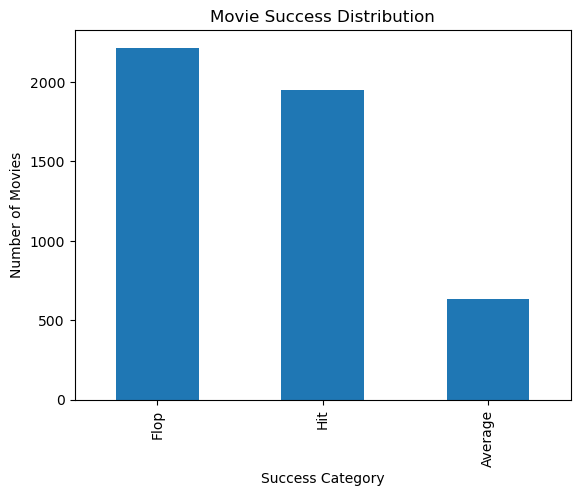

In [11]:
# Success Distribution
df['success'].value_counts().plot(kind='bar')
plt.title("Movie Success Distribution")
plt.xlabel("Success Category")
plt.ylabel("Number of Movies")
plt.show()

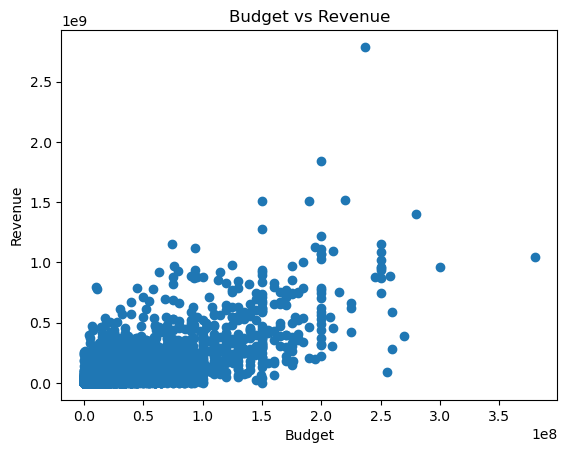

In [12]:
# Budget vs Revenue
plt.scatter(df['budget'], df['revenue'])
plt.title("Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")
plt.show()

                                              genres  \
0  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                    genres_clean  
0  [Action, Adventure, Fantasy, Science Fiction]  
1                   [Adventure, Fantasy, Action]  
2                     [Action, Adventure, Crime]  
3               [Action, Crime, Drama, Thriller]  
4           [Action, Adventure, Science Fiction]  


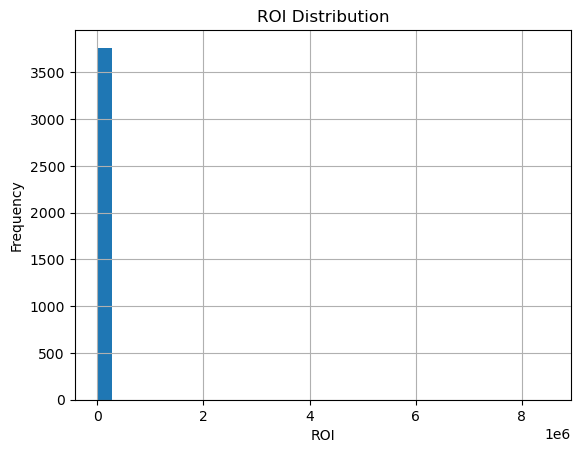

In [13]:
# ROI Distribution


def extract_genres(x):
    try:
        return [g['name'] for g in ast.literal_eval(x)]
    except:
        return []

df['genres_clean'] = df['genres'].apply(extract_genres)

print(df[['genres', 'genres_clean']].head())
df['genres_clean'] = df['genres_clean'].apply(lambda x: x if isinstance(x, list) else [])
df['roi'] = pd.to_numeric(df['roi'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=['roi'])

df['roi'].hist(bins=30)
plt.title("ROI Distribution")
plt.xlabel("ROI")
plt.ylabel("Frequency")
plt.show()

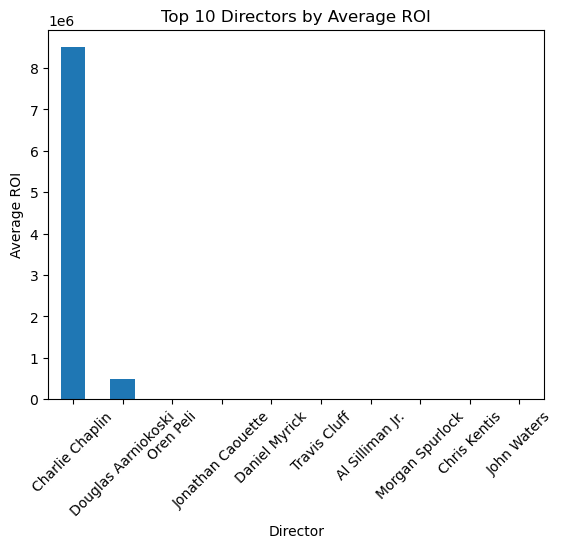

In [14]:
# Top Directors (Average ROI)
top_directors = df.groupby('director')['roi'].mean().sort_values(ascending=False).head(10)

top_directors.plot(kind='bar')
plt.title("Top 10 Directors by Average ROI")
plt.xlabel("Director")
plt.ylabel("Average ROI")
plt.xticks(rotation=45)
plt.show()

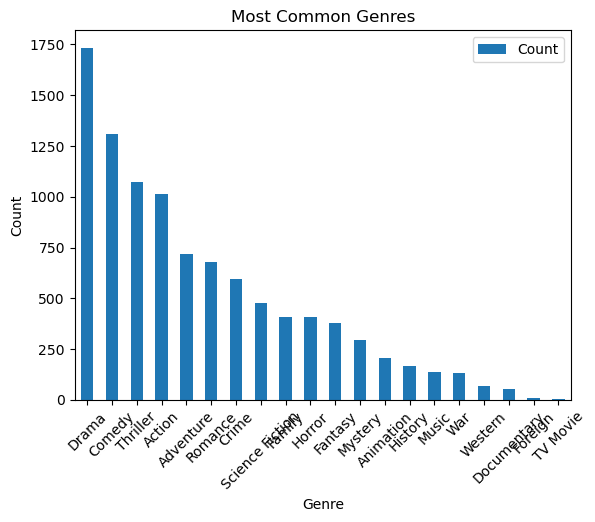

In [15]:
# Genre Analysis
from collections import Counter

all_genres = []

for g in df['genres_clean']:
    all_genres.extend(g)

genre_counts = Counter(all_genres)

genres_df = pd.DataFrame(genre_counts.items(), columns=['Genre', 'Count'])
genres_df = genres_df.sort_values(by='Count', ascending=False)

genres_df.plot(kind='bar', x='Genre', y='Count')
plt.title("Most Common Genres")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

# API INTEGRATION

In [16]:
import requests

api_key = "802c8c9f632bfe485790a596c8fbaecd"

movie_id = 19995 

url = f"https://api.themoviedb.org/3/movie/{movie_id}?api_key={api_key}"

response = requests.get(url)
data = response.json()

print(data['runtime'])
print(data['vote_average'])

162
7.606


In [17]:
movie_info = {
    "title": data.get("title"),
    "runtime": data.get("runtime"),
    "vote_average": data.get("vote_average"),
    "vote_count": data.get("vote_count"),
    "genres": [g["name"] for g in data.get("genres", [])],
    "budget": data.get("budget"),
    "revenue": data.get("revenue")
}

print(movie_info)

{'title': 'Avatar', 'runtime': 162, 'vote_average': 7.606, 'vote_count': 34044, 'genres': ['Science Fiction', 'Action', 'Adventure'], 'budget': 237000000, 'revenue': 2923706026}


# Add API Data to Dataset

In [18]:
import pandas as pd
import time

API_KEY = "802c8c9f632bfe485790a596c8fbaecd"

sample_df = df.head(50).copy()

def fetch_movie_data(movie_id):
    url = f"https://api.themoviedb.org/3/movie/{movie_id}?api_key={API_KEY}"
    r = requests.get(url)
    if r.status_code == 200:
        return r.json()
    return None

runtimes = []

for mid in sample_df['id']:
    data = fetch_movie_data(mid)
    if data:
        runtimes.append(data.get("runtime"))
    else:
        runtimes.append(None)
    
    time.sleep(0.2)  # avoid rate limit

sample_df["api_runtime"] = runtimes

print(sample_df[["title", "api_runtime"]].head())

                                      title  api_runtime
0                                    Avatar          162
1  Pirates of the Caribbean: At World's End          169
2                                   Spectre          148
3                     The Dark Knight Rises          165
4                               John Carter          132


# Movie Search Tool

In [19]:
def search_movie(df, movie_name):
    result = df[df['title'].str.contains(movie_name, case=False, na=False)]
    
    if result.empty:
        print("Movie not found.")
        return
    
    for _, row in result.iterrows():
        print("\n🎬 Movie Details")
        print("Title:", row['title'])
        print("Director:", row['director'])
        print("Budget:", row['budget'])
        print("Revenue:", row['revenue'])
        print("Profit:", row['profit'])
        print("ROI:", row['roi'])
        print("Success:", row['success'])
        print("Genres:", row['genres_clean'])
        print("Cast:", row['cast_top3'])

# Example usage
search_movie(df, "Titanic")


🎬 Movie Details
Title: Titanic
Director: James Cameron
Budget: 200000000
Revenue: 1845034188
Profit: 1645034188
ROI: 8.22517094
Success: Hit
Genres: ['Drama', 'Romance', 'Thriller']
Cast: ['Kate Winslet', 'Leonardo DiCaprio', 'Frances Fisher']


# Movie Comparison Tool

In [20]:
def compare_movies(df, movie1, movie2):
    m1 = df[df['title'].str.contains(movie1, case=False, na=False)]
    m2 = df[df['title'].str.contains(movie2, case=False, na=False)]
    
    if m1.empty or m2.empty:
        print("One or both movies not found.")
        return
    
    m1 = m1.iloc[0]
    m2 = m2.iloc[0]
    
    print("\n🎬 MOVIE COMPARISON\n")
    
    print("📌 Title:", m1['title'], "vs", m2['title'])
    print("💰 Budget:", m1['budget'], "vs", m2['budget'])
    print("💵 Revenue:", m1['revenue'], "vs", m2['revenue'])
    print("📈 Profit:", m1['profit'], "vs", m2['profit'])
    print("📊 ROI:", m1['roi'], "vs", m2['roi'])
    print("🎯 Success:", m1['success'], "vs", m2['success'])
    print("🎭 Director:", m1['director'], "vs", m2['director'])

# Example usage
compare_movies(df, "Batman", "Avatar")


🎬 MOVIE COMPARISON

📌 Title: Batman v Superman: Dawn of Justice vs Avatar
💰 Budget: 250000000 vs 237000000
💵 Revenue: 873260194 vs 2787965087
📈 Profit: 623260194 vs 2550965087
📊 ROI: 2.493040776 vs 10.763565767932489
🎯 Success: Hit vs Hit
🎭 Director: Zack Snyder vs James Cameron
